# Image Classification: Pretrained ResNet18 vs Baseline
Fine-tunes a pretrained ResNet18 (PyTorch) on a CIFAR-10 subset and compares it with a logistic-regression baseline on raw pixels.



In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

torch.manual_seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


## 1. Data: CIFAR-10 subset (5,000 train / 2,000 test images, 10 classes)

In [2]:
N_TRAIN, N_TEST = 5000, 2000
raw_train = datasets.CIFAR10("data", train=True, download=True)
raw_test = datasets.CIFAR10("data", train=False, download=True)
classes = raw_train.classes

train_idx = np.random.permutation(len(raw_train))[:N_TRAIN]
test_idx = np.random.permutation(len(raw_test))[:N_TEST]
print(classes)

100%|██████████| 170M/170M [1:09:39<00:00, 40.8kB/s]


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 2. Baseline: logistic regression on raw pixels

In [3]:
Xtr = raw_train.data[train_idx].reshape(N_TRAIN, -1) / 255.0
ytr = np.array(raw_train.targets)[train_idx]
Xte = raw_test.data[test_idx].reshape(N_TEST, -1) / 255.0
yte = np.array(raw_test.targets)[test_idx]

baseline = LogisticRegression(max_iter=200)
baseline.fit(Xtr, ytr)
baseline_acc = accuracy_score(yte, baseline.predict(Xte))
print(f"Baseline accuracy: {baseline_acc:.3f}")

Baseline accuracy: 0.318


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 3. Fine-tune pretrained ResNet18

In [4]:
tf = transforms.Compose([
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
train_ds = Subset(datasets.CIFAR10("data", train=True, transform=tf), train_idx)
test_ds = Subset(datasets.CIFAR10("data", train=False, transform=tf), test_idx)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=128)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

opt = torch.optim.Adam(model.parameters(), lr=3e-4)
loss_fn = nn.CrossEntropyLoss()

def evaluate():
    model.eval(); preds, labels = [], []
    with torch.no_grad():
        for x, y in test_dl:
            preds += model(x.to(device)).argmax(1).cpu().tolist(); labels += y.tolist()
    return np.array(labels), np.array(preds)

EPOCHS = 3
for epoch in range(EPOCHS):
    model.train(); total = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
        total += loss.item() * len(x)
    labels, preds = evaluate()
    print(f"Epoch {epoch+1}/{EPOCHS}  train loss {total/N_TRAIN:.3f}  test acc {accuracy_score(labels, preds):.3f}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 195MB/s]


Epoch 1/3  train loss 0.961  test acc 0.745
Epoch 2/3  train loss 0.299  test acc 0.798
Epoch 3/3  train loss 0.131  test acc 0.806


## 4. Results

Baseline (logistic regression): 31.8%
Fine-tuned ResNet18:            80.6%

              precision    recall  f1-score   support

    airplane       0.77      0.82      0.79       185
  automobile       0.89      0.89      0.89       201
        bird       0.82      0.74      0.78       215
         cat       0.70      0.72      0.71       199
        deer       0.77      0.74      0.76       205
         dog       0.70      0.75      0.72       198
        frog       0.82      0.84      0.83       196
       horse       0.88      0.77      0.82       199
        ship       0.85      0.91      0.88       199
       truck       0.86      0.89      0.87       203

    accuracy                           0.81      2000
   macro avg       0.81      0.81      0.81      2000
weighted avg       0.81      0.81      0.81      2000



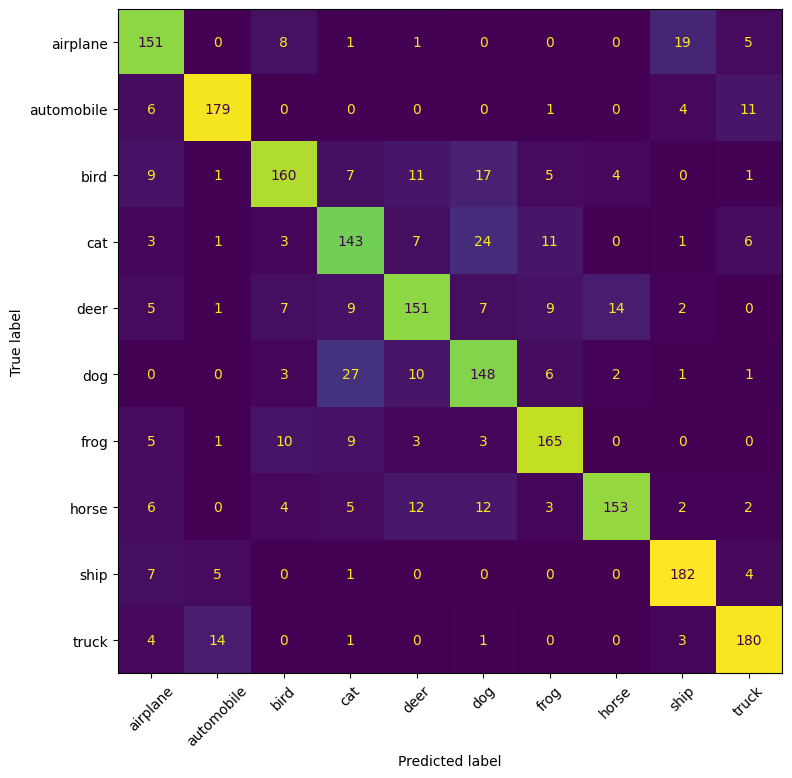

In [5]:
labels, preds = evaluate()
resnet_acc = accuracy_score(labels, preds)
print(f"Baseline (logistic regression): {baseline_acc:.1%}")
print(f"Fine-tuned ResNet18:            {resnet_acc:.1%}")
print()
print(classification_report(labels, preds, target_names=classes))

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(labels, preds), display_labels=classes).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

## 5. Summary
- **Dataset:** CIFAR-10 subset, 5,000 train / 2,000 test images, 10 classes
- **Baseline accuracy (logistic regression on raw pixels):** 31.8%
- **ResNet18 accuracy (fine-tuned, 3 epochs):** 80.6%
- **Improvement over baseline:** about 49 percentage points
- **Best classes:** automobile (F1 0.89), ship (0.88), truck (0.87)
- **Most confused classes:** dog and cat (27 and 24 misclassifications), airplane and ship (19), truck and automobile (14 and 11)
- **Next steps:** more epochs, data augmentation, higher-resolution images, and the full 50,000-image dataset